# Search, gradients and transfer

Research scratchpad 2/2. Separate optimizer implementation, derivative observability, returned-action choice and continuous control. This notebook reanalyzes saved evidence only. It runs independently of notebook 1 with NumPy, pandas and Matplotlib, and does not load models, run physics or write files. Every cohort stays separate.

In [1]:
from pathlib import Path
from io import BytesIO
import hashlib, json, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Works from this folder or the repository root. Nothing is extracted or written.
HERE = (
    Path.cwd()
    if (Path.cwd() / "evidence.zip").is_file()
    else Path.cwd() / "auto_research"
)
provenance = json.loads((HERE / "provenance.json").read_text())
assert (
    hashlib.sha256((HERE / "evidence.zip").read_bytes()).hexdigest()
    == provenance["archive_sha256"]
)
archive = zipfile.ZipFile(HERE / "evidence.zip")
for item in provenance["files"]:
    assert (
        hashlib.sha256(archive.read(item["archive_path"])).hexdigest() == item["sha256"]
    )


def read_json(path):
    return json.loads(archive.read("docs/" + path))


def read_csv(path):
    return pd.read_csv(BytesIO(archive.read("docs/" + path)))


def read_arrays(path):
    # Materialize only this small archive; reject pickle-backed object arrays.
    with np.load(BytesIO(archive.read("docs/" + path)), allow_pickle=False) as saved:
        return {name: saved[name] for name in saved.files}


def paired_interval(matrix, seed):
    # Each row is a bank, each column a task. Repeated heads are averaged FIRST.
    matrix = np.asarray(matrix, float)
    assert matrix.ndim == 2 and min(matrix.shape) >= 2 and np.isfinite(matrix).all()
    banks, tasks = matrix.shape
    rng = np.random.default_rng(seed)
    chosen = rng.integers(banks, size=(10000, banks, 1))
    within = rng.integers(tasks, size=(10000, banks, tasks))
    draws = matrix[chosen, within].mean(axis=(1, 2))
    return np.array([matrix.mean(), *np.quantile(draws, [0.025, 0.975])])


def physical_error(poses, goal):
    position = np.linalg.norm(poses[..., :2] - goal[..., :2], axis=-1)
    angle = (poses[..., 2] - goal[..., 2] + np.pi) % (2 * np.pi) - np.pi
    return np.sqrt(position**2 + (50 * angle) ** 2)


plt.rcParams.update(
    {"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False}
)
print("Verified byte-identical evidence files:", len(provenance["files"]))
print("Source base:", provenance["base_revision"])


Verified byte-identical evidence files: 236
Source base: d07cd7878cb40ecbd9e1004ef7db6794eb08d1df


## 1. Check optimizer semantics before interpreting gradients

The recorded synthetic audit found that the vendored planner constructs Adam but does not apply it; its advertised Adam matches the SGD update. A separate tested refinement helper was implemented in the original research without changing upstream files. This cell verifies saved audit outputs, not a fresh optimizer execution. The source hash identifies the audited version.

An elite mean can also be worse than the best evaluated sample. This is a return convention, not by itself a PushT failure or a novel optimization insight.

In [2]:
audit = read_json("planner_optimizer_audit.json")
actions = audit["adam_update"]["actions"]
np.testing.assert_array_equal(actions["upstream_adam"], actions["upstream_sgd"])
assert not np.allclose(actions["upstream_adam"], actions["reference_adam"])
print(
    pd.DataFrame({name: np.asarray(value).ravel() for name, value in actions.items()})
)
print("Audited source SHA-256:", audit["upstream_source_sha256"])
# Exact explanatory counterexample: both evaluated actions have zero cost.
x = np.array([-1.0, 1.0])
cost = lambda action: (action**2 - 1) ** 2
assert cost(x).min() == 0 and cost(x.mean()) == 1
print("Best sample cost:", cost(x).min(), "| elite-mean cost:", cost(x.mean()))


   upstream_sgd  upstream_adam  reference_sgd  reference_adam
0          0.36           0.36           0.36        0.199598
1          1.92           1.92           1.92        0.199839
Audited source SHA-256: 6b673d10b30cd66d07b09daa7b96397f367f49387c443731b6d7d2fd148cc0e3
Best sample cost: 0.0 | elite-mean cost: 1.0


## 2. Near-hold audit: correct model calculus, flat object responses

Twelve exploratory tasks, three banks and three repeated scales. Coordinate secants are finite differences through contact and rasterization, not certified smooth derivatives. Flat vectors make cosines undefined; filling them with zero would invent alignment measurements. The common-descent direction was an established multiobjective diagnostic, not a new projection theorem.

In [3]:
a = read_arrays("planning_gradient_results/audit_vectors.npz")
metadata = read_json("planning_gradient_results/audit_task_metadata.json")
assert len(metadata) == 12 and len({r["seed"] for r in metadata}) == 3
assert all((r["correctness"]["passed"] for r in metadata))
steps = np.array([0.05, 0.2, 0.5])
for gradient, costs in [("g_encoded", "encoded_costs"), ("g_object", "object_costs")]:
    pairs = a[costs][:, 1:61].reshape(12, 3, 10, 2)
    reconstructed = (pairs[..., 0] - pairs[..., 1]) / (2 * steps[None, :, None])
    np.testing.assert_allclose(reconstructed, a[gradient], rtol=1e-12, atol=1e-12)
assert np.all(np.linalg.norm(a["g_object"], axis=-1) <= 1e-10)
print(
    "Nonflat object vectors per scale:",
    (np.linalg.norm(a["g_object"], axis=-1) > 1e-10).sum(axis=0),
)
print("Object-linked cosines: undefined for all 12 tasks at all three scales.")
directions = pd.DataFrame(
    [{"seed": t["seed"], **r} for t in metadata for r in t["direction_tests"]]
)
print(
    directions.groupby(["method", "step"])
    .object_error_change.agg(["mean", "min", "max"])
    .round(6)
)


Nonflat object vectors per scale: [0 0 0]
Object-linked cosines: undefined for all 12 tasks at all three scales.
                                     mean       min  max
method                     step                         
exploratory_common_descent 0.05  0.000000  0.000000  0.0
                           0.20  0.000000  0.000000  0.0
                           0.50  0.000000  0.000000  0.0
negative_model_gradient    0.05  0.000000  0.000000  0.0
                           0.20  0.000000  0.000000  0.0
                           0.50 -0.167586 -2.011033  0.0


There is no demonstrated gradient-planning improvement here, nor evidence that it is impossible. The later supplement asks whether sensitivity becomes observable at actions actually visited by visual planning.

## 3. Planner-visited supplement: observability, not better control

Twenty fresh paired tasks from ten banks. Compare normalized-zero near-hold with the visual CEM evaluated incumbent. Physics never chooses that point. At steps 0.05, 0.20 and 0.50, full central or inward one-sided pairs use their actual float32 denominators. All flat, no-contact and tied cases remain included. The primary scale is 0.20.

In [4]:
manifest = read_json("planner_visited_gradient_results/audit/manifest.json")
expected = [(s, t) for s in range(20270011, 20270021) for t in range(2)]
assert [(r["bank_seed"], r["task_id"]) for r in manifest["records"]] == expected
assert manifest["status"] == "completed"


def cosine(left, right):
    # Return NaN, never zero, when either vector is flat.
    nl, nr = (np.linalg.norm(left), np.linalg.norm(right))
    return float(np.dot(left, right) / (nl * nr)) if min(nl, nr) > 1e-10 else np.nan


observations = []
for record in manifest["records"]:
    base = f"planner_visited_gradient_results/audit/seed_{record['bank_seed']}/task_{record['task_id']:03}/"
    inputs = read_arrays(base + "inputs.npz")
    d = read_arrays(base + "diagnostics.npz")
    plan = read_arrays(base + "planning.npz")
    assert all((c["passed"] for c in record["correctness"]))
    incumbent = int(plan["incumbent_index"])
    assert incumbent == int(plan["evaluated_costs"].argmin())
    np.testing.assert_array_equal(
        plan["points"][1], plan["evaluated_actions"][incumbent]
    )
    # Recompute physical costs from saved terminal poses; no simulator needed.
    physical = physical_error(
        d["states"][:, -1, 2:5].astype(float), inputs["goal_pose"].astype(float)
    )
    np.testing.assert_allclose(
        physical.reshape(2, 61), d["object_costs"], rtol=0, atol=1e-12
    )
    for point in range(2):
        denominator = inputs["denominators"][point]
        assert np.all(denominator != 0)
        for cost, gradient in [
            ("encoded_costs", "g_encoded"),
            ("object_costs", "g_object"),
            ("imagined_probe_costs", "g_imagined"),
        ]:
            pairs = (
                d[cost][point]
                if cost == "imagined_probe_costs"
                else d[cost][point, 1:].reshape(3, 10, 2)
            )
            np.testing.assert_allclose(
                (pairs[..., 0] - pairs[..., 1]) / denominator,
                d[gradient][point],
                rtol=0,
                atol=1e-12,
            )
        for k, step in enumerate(steps):
            encoded, obj, imagined = (
                d["g_encoded"][point, k],
                d["g_object"][point, k],
                d["g_imagined"][point, k],
            )
            observations.append(
                {
                    "bank": record["bank_seed"],
                    "task": record["task_id"],
                    "point": point,
                    "step": step,
                    "object_norm": np.linalg.norm(obj),
                    "imagined_vs_visual": cosine(imagined, encoded),
                    "visual_vs_object": cosine(encoded, obj),
                    "autograd_vs_imagined": cosine(d["autograd"][point], imagined),
                    "one_sided": int(
                        np.count_nonzero(inputs["stencil_modes"][point, k])
                    ),
                }
            )
obs = pd.DataFrame(observations)
assert len(obs) == 120
counts = (
    obs.assign(nonflat=obs.object_norm > 1e-10)
    .groupby(["point", "step"])
    .nonflat.sum()
    .unstack("step")
)
print("Nonflat object secants /20:", counts, sep=chr(10))
primary = (
    obs.query("step == .20").pivot(
        index=["bank", "task"], columns="point", values="object_norm"
    )
    > 1e-10
)
contrast = (primary[1].astype(float) - primary[0]).unstack("task")
result = paired_interval(contrast, 20270901)
np.testing.assert_allclose(result, [0.4, 0.15, 0.65], atol=1e-12)
print("Paired planned-minus-near-hold fraction, lower95, upper95:", result)
print("Threshold sensitivity:")
for threshold in [1e-08, 0.0001, 0.01]:
    print(
        threshold,
        obs.assign(active=obs.object_norm > threshold)
        .groupby(["point", "step"])
        .active.sum()
        .tolist(),
    )
print(
    "One-sided coordinates per 200:",
    obs.groupby(["point", "step"]).one_sided.sum().tolist(),
)


Nonflat object secants /20:
step   0.05  0.20  0.50
point                  
0         0     1     3
1         9     9     9
Paired planned-minus-near-hold fraction, lower95, upper95: [0.4  0.15 0.65]
Threshold sensitivity:
1e-08 [0, 1, 3, 9, 9, 9]
0.0001 [0, 1, 3, 9, 9, 9]
0.01 [0, 1, 3, 9, 9, 9]
One-sided coordinates per 200: [0, 0, 0, 16, 24, 33]


           imagined_vs_visual       visual_vs_object       autograd_vs_imagined      
                         mean count             mean count                 mean count
point step                                                                           
0     0.05              0.186    19              NaN     0                1.000    20
      0.20              0.725    20            0.809     1                0.906    20
      0.50              0.615    20           -0.630     3                0.606    20
1     0.05              0.231    20            0.240     9                0.998    20
      0.20              0.501    20            0.262     9                0.750    20
      0.50              0.526    20            0.534     9                0.543    20


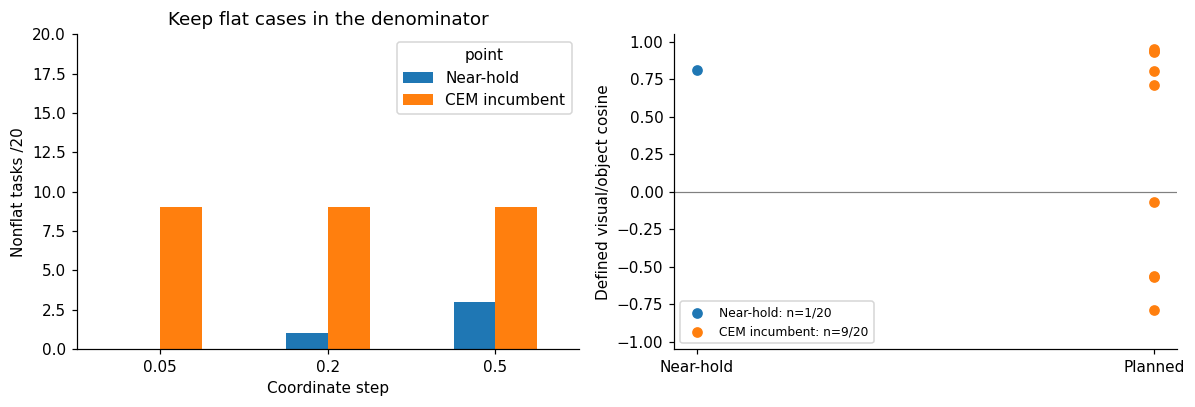

In [5]:
links = ["imagined_vs_visual", "visual_vs_object", "autograd_vs_imagined"]
# pandas excludes NaN from means/counts; show the missing denominator explicitly.
conditional = obs.groupby(["point", "step"])[links].agg(["mean", "count"])
print(conditional.round(3).to_string())
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
counts.T.rename(columns={0: "Near-hold", 1: "CEM incumbent"}).plot.bar(
    ax=axes[0], rot=0
)
axes[0].set(
    ylim=(0, 20),
    ylabel="Nonflat tasks /20",
    xlabel="Coordinate step",
    title="Keep flat cases in the denominator",
)
values = obs.query("step == .20")
for point, label in [(0, "Near-hold"), (1, "CEM incumbent")]:
    defined = values.query("point == @point").visual_vs_object.dropna()
    axes[1].scatter(
        np.full(len(defined), point), defined, label=f"{label}: n={len(defined)}/20"
    )
axes[1].axhline(0, color="grey", lw=0.8)
axes[1].set(
    xticks=[0, 1],
    xticklabels=["Near-hold", "Planned"],
    ylabel="Defined visual/object cosine",
    ylim=(-1.05, 1.05),
)
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()


At the primary scale, 1/20 near-hold versus 9/20 planned tasks are nonflat: +0.400 [0.150, 0.650]. This is an exploratory evaluation-point contrast, not an optimizer update, contact-causality result or reward gain. Conditional cosines have sometimes tiny denominators. A high autograd/imagined cosine checks model calculus, not real physical alignment.

## 4. CEM return rule: supported one-step confirmation

Final elite mean versus best explicitly evaluated incumbent under the same 130 candidate queries. Twelve development tasks precede a fresh 100-task confirmation. Best-seen returns are established iCEM prior art. An imagined-cost inequality is guaranteed; physical benefit must be tested separately.

In [6]:
a = read_arrays("cem_return_rule_results/task_arrays.npz")
mask = a["phase"] == "locked"
assert mask.sum() == 100
costs = a["evaluated_costs"][mask]
indices = a["selected_indices"][mask]
assert costs.shape == (100, 130) and np.all(indices[:, 0] == 129)
np.testing.assert_array_equal(indices[:, 1], costs.argmin(axis=1))
np.testing.assert_array_equal(
    a["returned_normalized_actions"][mask],
    a["evaluated_actions"][mask][np.arange(100)[:, None], indices],
)
errors = physical_error(
    a["returned_states"][mask, :, -1, 2:5].astype(float),
    a["goal_pose"][mask, None, :].astype(float),
)
frame = pd.DataFrame(
    {
        "bank": a["bank_seed"][mask],
        "task": a["task_id"][mask],
        "gain": errors[:, 0] - errors[:, 1],
    }
)
assert not frame.duplicated(["bank", "task"]).any()
matrix = frame.pivot(index="bank", columns="task", values="gain")
# Match the original CEM bootstrap's bank-grouped RNG draw order exactly.
banks = matrix.to_numpy()
rng = np.random.default_rng(20266901)
chosen = rng.integers(10, size=(10000, 10))
within = np.empty(chosen.shape)
for index, bank in enumerate(banks):
    selected_bank = chosen == index
    draws = rng.integers(len(bank), size=(int(selected_bank.sum()), len(bank)))
    within[selected_bank] = bank[draws].mean(axis=1)
result = np.array([banks.mean(), *np.quantile(within.mean(axis=1), [0.025, 0.975])])
saved = read_json("cem_return_rule_results/summary.json")["locked"]
np.testing.assert_allclose(
    result,
    [saved["mean_primary_improvement"], *saved["paired_hierarchical_95_interval"]],
    atol=1e-10,
)
print("Physical error A/B:", errors.mean(axis=0))
print("Gain, lower95, upper95:", result)
print("Positive banks:", int((matrix.mean(axis=1) > 0).sum()))
print(
    "Improved / worsened / tied:",
    [
        (frame.gain > 1e-06).sum(),
        (frame.gain < -1e-06).sum(),
        (frame.gain.abs() <= 1e-06).sum(),
    ],
)
assert result[0] >= 0.5 and result[1] > 0 and ((matrix.mean(axis=1) > 0).sum() >= 8)


Physical error A/B: [24.81868996 19.84284472]
Gain, lower95, upper95: [4.97584524 3.24111788 6.92723305]
Positive banks: 10
Improved / worsened / tied: [59, 3, 38]


One-step gain: +4.976 [3.241, 6.927], ten positive banks; 59 improved, 3 worsened, 38 tied. This is not a new optimizer or an automatically transferable closed-loop result.

## 5. Three-replan continuous transfer: not supported

Twenty separate tasks, ten banks, three real replans of one five-control imagined step. The ordinary prototype, not the learned adapter, is used. Each arm carries continuous physical dynamics through all fifteen controls. Six independent streams per task cost 780 queries; after divergence, no cross-arm sharing is claimed.

Final error A/B: [11.45903029  9.74316958]
Gain, lower95, upper95: [ 1.71586071 -1.87023119  5.60082712] | positive banks: 6
Improved / worsened / tied: [10, 7, 3]


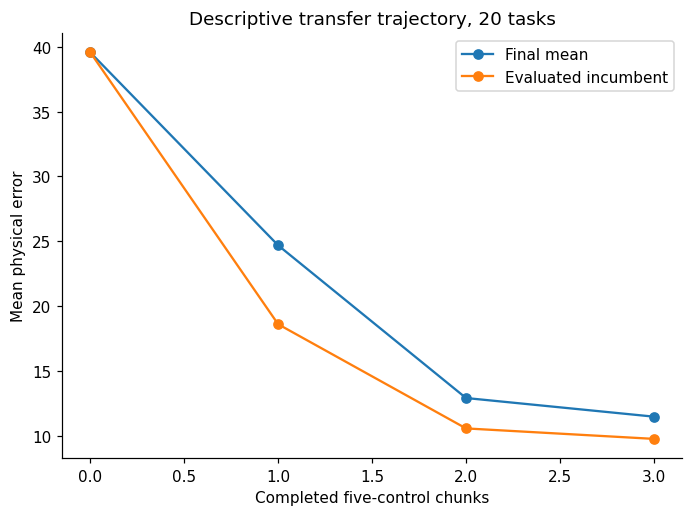

In [7]:
a = read_arrays("cem_closed_loop_results/task_arrays.npz")
records = read_json("cem_closed_loop_results/task_metadata.json")
assert a["states"].shape == (20, 2, 16, 7) and a["body_states"].shape == (20, 2, 16, 18)
assert a["evaluated_costs"].shape == (20, 2, 3, 130)
selected = a["selected_indices"]
assert np.all(selected[:, 0] == 129)
np.testing.assert_array_equal(
    selected[:, 1], a["evaluated_costs"][:, 1].argmin(axis=-1)
)
for arm in range(2):
    for step in range(3):
        np.testing.assert_array_equal(
            a["actions"][:, arm, 5 * step : 5 * (step + 1)],
            a["evaluated_actions"][np.arange(20), arm, step, selected[:, arm, step]],
        )
errors = physical_error(
    a["states"][..., 2:5].astype(float), a["goal_pose"][:, None, None, :].astype(float)
)
np.testing.assert_allclose(errors, a["object_errors_every_control"], rtol=0, atol=1e-12)
frame = pd.DataFrame(
    {
        "bank": [r["bank_seed"] for r in records],
        "task": [r["task_id"] for r in records],
        "gain": errors[:, 0, -1] - errors[:, 1, -1],
    }
)
matrix = frame.pivot(index="bank", columns="task", values="gain")
result = paired_interval(matrix, 20268901)
saved = read_json("cem_closed_loop_results/summary.json")["effect"]
np.testing.assert_allclose(result, [saved["mean"], *saved["interval"]], atol=1e-12)
print("Final error A/B:", errors[:, :, -1].mean(axis=0))
print(
    "Gain, lower95, upper95:",
    result,
    "| positive banks:",
    int((matrix.mean(axis=1) > 0).sum()),
)
print(
    "Improved / worsened / tied:",
    [
        (frame.gain > 1e-06).sum(),
        (frame.gain < -1e-06).sum(),
        (frame.gain.abs() <= 1e-06).sum(),
    ],
)
for arm, label in enumerate(["Final mean", "Evaluated incumbent"]):
    plt.plot(
        [0, 1, 2, 3], errors[:, arm, [0, 5, 10, 15]].mean(axis=0), "o-", label=label
    )
plt.xlabel("Completed five-control chunks")
plt.ylabel("Mean physical error")
plt.title("Descriptive transfer trajectory, 20 tasks")
plt.legend()
plt.tight_layout()
plt.show()


Final error 11.459 → 9.743 gives +1.716 [−1.870, 5.601], only six positive banks, below eight required. Ten improved, seven worsened and three tied. Favorable mean, insufficient support, not equivalence. Saved body velocities support continuity, but this notebook checks stored certificates rather than replaying physics.

## 6. Metric × search: engineering only, pilot unopened

The four-arm implementation combines prototype/learned cost with mean/incumbent return. Original-cost and full-control replay checks passed on a permanently retired engineering task. The prospective time gate stopped execution before any of six pilot cases or pilot freeze opened. No interaction or combined adapter-plus-CEM gain exists.

In [8]:
s = read_json("metric_search_factorial_design/summary.json")
assert s["scientific_cases_completed"] == 0 and s["scientific_cases_planned"] == 6
assert s["no_scientific_effect_estimate"]
p = s["timing_projection"]
shortfall = p["projected_remaining_seconds"] - p["available_seconds"]
np.testing.assert_allclose(shortfall, s["shortfall_seconds"], atol=1e-09)
print("Opened scientific cases:", s["scientific_cases_completed"], "/6")
print("Time shortfall (seconds):", round(shortfall, 2))
print("Retired engineering task:", s["retired_engineering_label"])
print("Correctness evidence keys:", list(s["correctness"]))
print("No performance mean, factorial contrast or interaction is estimated.")
archive.close()


Opened scientific cases: 0 /6
Time shortfall (seconds): 35.2
Retired engineering task: [20269000, 0]
Correctness evidence keys: ['cached_selected_cost_checks', 'continuous_dynamics', 'full_initial_sequence_replays', 'initial_body18_equal', 'initial_resets_per_arm', 'original_adapter_score_equivalence', 'passed', 'within_metric_first_streams_equal']
No performance mean, factorial contrast or interaction is estimated.


## Limits and literature

These studies isolate different failure points, not a single proven causal chain. One checkpoint and short synthetic targets limit transfer. Small bank counts, local freezes and sequential exploration do not give external preregistration or family-wide error control. Historical source/config bytes and reconstructed task identities do not recover unavailable historical raw trajectories. Full study reports, frozen protocols and exact evidence mappings are retained in the sidecar.

Primary sources already checked in the original reports:
- [DINO-WM, Appendix A.5](https://arxiv.org/html/2411.04983v2#A5): action-gradient planning and CEM.
- [iCEM, Section 3.3 and Appendix E.3](https://proceedings.mlr.press/v155/pinneri21a/pinneri21a.pdf): best evaluated return rule.
- [Grad+CEM](https://proceedings.mlr.press/v120/bharadhwaj20a.html): interleaving gradient and sampling updates.
- [Control-Geometry Straightening](https://arxiv.org/html/2609.35603v1): related action/latent geometry and physical-effect identifiability, with assumptions that do not certify this checkpoint.

The contribution is controlled decision-level evidence and transparent negative results, not a new latent architecture, projection principle or hybrid planner. Any new experiment needs a fresh explicit protocol/resource plan; this consolidation opens no reserved data.